<!-- d2l:prose id=mf-md-1 fw=all -->

# Matrix Factorization

Matrix factorization represents each user and item by a low-dimensional vector
and predicts a rating from their inner product [@Koren.Bell.Volinsky.2009].
The method became prominent through the Netflix Prize, where factor models were
important components of the winning ensemble
[@Toscher.Jahrer.Bell.2009]. Its lasting value is conceptual as well as
practical: a sparse interaction matrix can be modeled through two compact sets
of embeddings, with parameters shared across all observed ratings.


## The Matrix Factorization Model

Let $\mathbf R\in\mathbb R^{m\times n}$ contain the explicit ratings of $m$
users for $n$ items. We approximate it by
$\hat{\mathbf R}=\mathbf P\mathbf Q^\top$, where
$\mathbf P\in\mathbb R^{m\times k}$ contains user embeddings and
$\mathbf Q\in\mathbb R^{n\times k}$ contains item embeddings, with $k\ll\min(m,n)$.

The row $\mathbf p_u$ represents user $u$, and $\mathbf q_i$ represents item
$i$. Their inner product is large when the two embeddings align. Individual
coordinates should not usually be read as fixed semantic attributes: rotating
both embedding spaces by the same orthogonal matrix leaves every prediction
unchanged. The model identifies a useful relative geometry, not a unique label
for each latent coordinate. The predicted matrix is

$$\hat{\mathbf{R}} = \mathbf{PQ}^\top$$

The plain inner product omits systematic offsets: some users give higher ratings
than others, and some items receive higher ratings across users. User and item
biases model these effects,

$$
\hat{\mathbf{R}}_{ui} = \mathbf{p}_u\mathbf{q}^\top_i + b_u + b_i
$$

We fit the model only on the observed set $\mathcal K$ and regularize all learned parameters:

$$
\underset{\mathbf P,\mathbf Q,\mathbf b^{(u)},\mathbf b^{(i)}}{\mathrm{argmin}}
\sum_{(u,i)\in\mathcal K}(R_{ui}-\hat R_{ui})^2
+\lambda\left(\|\mathbf P\|_F^2+\|\mathbf Q\|_F^2
+\|\mathbf b^{(u)}\|_2^2+\|\mathbf b^{(i)}\|_2^2\right).
$$

The loss does not treat missing entries as zero ratings. The coefficient
$\lambda$ penalizes embedding and bias magnitudes, and the parameters can be
fitted with stochastic gradient methods.

![Matrix factorization looks up a user embedding $\mathbf p_u$ and an item embedding $\mathbf q_i$. Their inner product, together with user and item biases, predicts $R_{ui}$; the parameters share information across the sparse interaction matrix.](../img/rec-mf.svg)

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

<!-- d2l:prose id=mf-md-2 fw=all -->

## Model Implementation

First, we implement the matrix factorization model described above. The user and item latent factors can be created with the `nn.Embedding`. The number of rows of an embedding is the number of items/users and its width is the dimension of the latent factors $k$.  We can also use `nn.Embedding` to create the user/item biases by setting the width to one. In the `forward` function, user and item ids are used to look up the embeddings.

<!-- d2l:prose id=mf-md-3 fw=pytorch -->

In PyTorch, the number of rows and the width are the `num_embeddings` and `embedding_dim` arguments.

In [2]:
class MF(nn.Module):
    def __init__(self, num_factors, num_users, num_items):
        super().__init__()
        self.P = nn.Embedding(num_users, num_factors)
        self.Q = nn.Embedding(num_items, num_factors)
        self.user_bias = nn.Embedding(num_users, 1)
        self.item_bias = nn.Embedding(num_items, 1)
        nn.init.normal_(self.P.weight, std=0.01)
        nn.init.normal_(self.Q.weight, std=0.01)
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.item_bias.weight)

    def forward(self, user_id, item_id):
        P_u = self.P(user_id)
        Q_i = self.Q(item_id)
        b_u = self.user_bias(user_id)
        b_i = self.item_bias(item_id)
        outputs = (P_u * Q_i).sum(dim=1) + b_u.squeeze() + b_i.squeeze()
        return outputs.flatten()

<!-- d2l:prose id=mf-md-4 fw=all -->

## Evaluation Measures

We then implement the RMSE (root-mean-square error) measure, which is commonly used to measure the differences between rating scores predicted by the model and the actually observed ratings (ground truth) [@Gunawardana.Shani.2015]. RMSE is defined as:

$$
\textrm{RMSE} = \sqrt{\frac{1}{|\mathcal{T}|}\sum_{(u, i) \in \mathcal{T}}(\mathbf{R}_{ui} -\hat{\mathbf{R}}_{ui})^2}
$$

where $\mathcal{T}$ is the set consisting of pairs of users and items that you want to evaluate on. $|\mathcal{T}|$ is the size of this set.

<!-- d2l:prose id=mf-md-5 fw=pytorch -->

We accumulate the squared errors over the test set and take the square root.

In [3]:
def evaluator(net, test_iter, devices):
    net.eval()
    sq_err_total, n = 0.0, 0
    with torch.no_grad():
        for users, items, ratings in test_iter:
            users, items, ratings = (users.to(devices[0]),
                                     items.to(devices[0]),
                                     ratings.to(devices[0]))
            preds = net(users, items)
            sq_err_total += ((preds - ratings) ** 2).sum().item()
            n += ratings.numel()
    return (sq_err_total / n) ** 0.5

<!-- d2l:prose id=mf-md-6 fw=all -->

## Training and Evaluating the Model


In the training function, we adopt the $\ell_2$ loss with weight decay. The weight decay mechanism has the same effect as the $\ell_2$ regularization.

In [4]:

def train_recsys_rating(net, train_iter, test_iter, loss, trainer, num_epochs,
                        devices=d2l.try_all_gpus(), evaluator=None,
                        **kwargs):
    net = net.to(devices[0])
    timer = d2l.Timer()
    animator = d2l.Animator(xlabel='epoch', xlim=[1, num_epochs], ylim=[0, 2],
                            legend=['train loss', 'test RMSE'])
    for epoch in range(num_epochs):
        net.train()
        metric, l = d2l.Accumulator(3), 0.
        for i, values in enumerate(train_iter):
            timer.start()
            users, items, ratings = [v.to(devices[0]) for v in values]
            trainer.zero_grad()
            preds = net(users, items)
            ls = loss(preds, ratings)
            ls.backward()
            trainer.step()
            l += ls.item()
            metric.add(ls.item() * users.shape[0], users.shape[0],
                       users.shape[0])
            timer.stop()
        if len(kwargs) > 0:  # It will be used in section AutoRec
            test_rmse = evaluator(net, test_iter, kwargs['inter_mat'],
                                  devices)
        else:
            test_rmse = evaluator(net, test_iter, devices)
        train_l = l / (i + 1)
        animator.add(epoch + 1, (train_l, test_rmse))
    print(f'train loss {metric[0] / metric[1]:.3f}, '
          f'test RMSE {test_rmse:.3f}')
    print(f'{metric[2] * num_epochs / timer.sum():.1f} examples/sec '
          f'on {str(devices)}')

<!-- d2l:prose id=mf-md-7 fw=all -->

Finally, let's put all things together and train the model. Here, we set the latent factor dimension to 30.

train loss 0.688, test RMSE 1.037
243178.7 examples/sec on [device(type='cuda', index=0)]


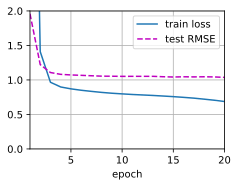

In [5]:
devices = d2l.try_all_gpus()
num_users, num_items, train_iter, test_iter = d2l.split_and_load_ml100k(
    test_ratio=0.1, batch_size=512)
net = MF(30, num_users, num_items)
loss = nn.MSELoss()
trainer = torch.optim.Adam(net.parameters(), lr=0.002, weight_decay=1e-5)
train_recsys_rating(net, train_iter, test_iter, loss, trainer, num_epochs=20,
                    devices=devices, evaluator=evaluator)

<!-- d2l:prose id=mf-md-8 fw=all -->

Below, we use the trained model to predict the rating that a user (ID 20) might give to an item (ID 30).

In [6]:
scores = net(torch.tensor([20], device=devices[0]),
             torch.tensor([30], device=devices[0]))
scores

tensor([2.8092], device='cuda:0', grad_fn=<AddBackward0>)

<!-- d2l:prose id=mf-md-9 fw=all -->

## Summary

* The matrix factorization model is widely used in recommender systems.  It can be used to predict ratings that a user might give to an item.
* We can implement and train matrix factorization for recommender systems.


## Exercises

1. `split_and_load_ml100k` defaults to `split_mode='seq-aware'`, so the test
   set above holds each user's most recent rating. Train `MF` with the same
   settings on `split_mode='random'` and report both test RMSEs. Explain the
   difference by what each test set asks the model to predict.
1. `MF` has no global offset, so its bias tables, initialized at zero, must
   absorb the mean rating of about 3.5. Add a learned global offset $\mu$, and
   write a second variant that keeps only $\mu + b_u + b_i$. Train both with
   the settings above and compare their test RMSEs with that of `MF` and with
   that of the constant prediction $\mu$ set to the training mean. How much of
   the improvement of `MF` over the constant comes from the biases?
1. In `train_recsys_rating`, the weight-decay setting of Adam adds
   $\lambda\boldsymbol\theta$ to the gradient of every parameter at every
   step, including the embedding rows of users who do not occur in the
   minibatch. Many SGD implementations instead minimize
   $\sum_{(u,i)\in\mathcal K}\big[(R_{ui}-\hat R_{ui})^2
   +\lambda(\|\mathbf p_u\|^2+\|\mathbf q_i\|^2)\big]$. For a user with $n_u$
   training ratings, count per epoch how often $\mathbf p_u$ is pulled toward
   zero under each scheme and under the objective of the text, which penalizes
   $\|\mathbf P\|_F^2$ once. Which scheme regularizes frequent users more
   strongly than rare ones?
1. Train `MF` with $k \in \{1, 5, 30, 100\}$ and weight decay
   $\in \{0, 10^{-5}, 10^{-3}\}$, and tabulate the final training loss and the
   test RMSE. The model has $(m+n)(k+1)$ parameters: at which $k$ does it
   have more parameters than training ratings? Does the test RMSE start to
   rise at the same $k$ for every weight decay?
1. Show that replacing $\mathbf P$ by $\mathbf P\mathbf A$ and $\mathbf Q$ by
   $\mathbf Q\mathbf A^{-\top}$ leaves every prediction unchanged for any
   invertible $\mathbf A$, and that the regularizer
   $\|\mathbf P\|_F^2+\|\mathbf Q\|_F^2$ is unchanged only for orthogonal
   $\mathbf A$. Then prove that
   $\min\{\tfrac12(\|\mathbf P\|_F^2+\|\mathbf Q\|_F^2) :
   \mathbf P\mathbf Q^\top=\mathbf X\}=\|\mathbf X\|_*$, the sum of the
   singular values of $\mathbf X$ (that section). For the
   upper bound, split the singular values evenly between the factors of the
   SVD $\mathbf X=\mathbf U\boldsymbol\Sigma\mathbf V^\top$. For the lower
   bound, write $\|\mathbf X\|_*=\operatorname{tr}(\mathbf U^\top\mathbf X
   \mathbf V)$ and apply the Cauchy--Schwarz inequality to
   $\langle\mathbf U^\top\mathbf P,\mathbf V^\top\mathbf Q\rangle_F$. What
   does this say about the rank of the matrices that the regularized objective
   prefers?

<!-- d2l:prose id=mf-md-10 fw=pytorch -->

[Discussions](https://d2l.discourse.group/t/400)